In [1]:
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler

# Gradient Boosted Decision Tree Frameworks
import lightgbm as lgb

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

# Bayesian Hyperparameter Optimization
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    OPTUNA_AVAILABLE = True
except ImportError:
    OPTUNA_AVAILABLE = False

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 100)

print(f"LightGBM Version: {lgb.__version__}")
print(f"CatBoost Available: {CATBOOST_AVAILABLE}")
print(f"XGBoost Available: {XGBOOST_AVAILABLE}")
print(f"Optuna Available: {OPTUNA_AVAILABLE}")

LightGBM Version: 4.7.0
CatBoost Available: True
XGBoost Available: True
Optuna Available: True


c:\python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print("--- Loading & Logically Imputing Supplementary Datasets ---")

# ==========================================
# 1. PRODUCTS: Impute weight via Volumetric Density
# ==========================================
df_products = pd.read_csv('products.csv')
df_products['vol_cm3'] = df_products['length_cm'] * df_products['width_cm'] * df_products['height_cm']

# Compute median physical density (kg / cm3) per category
known_products = df_products.dropna(subset=['weight_kg']).copy()
known_products['density'] = known_products['weight_kg'] / (known_products['vol_cm3'] + 1e-5)
cat_density = known_products.groupby('category')['density'].median()
overall_median_density = known_products['density'].median()

# Impute missing weight based on physical volume and category density
missing_weight_mask = df_products['weight_kg'].isnull()
df_products.loc[missing_weight_mask, 'weight_kg'] = (
    df_products.loc[missing_weight_mask, 'vol_cm3'] * 
    df_products.loc[missing_weight_mask, 'category'].map(cat_density).fillna(overall_median_density)
)
df_products['weight_is_imputed'] = missing_weight_mask.astype(np.int8)

# Stationary category-relative benchmarks
cat_stats = df_products.groupby('category').agg(
    cat_median_price=('list_price', 'median'),
    cat_median_weight=('weight_kg', 'median')
).reset_index()
df_products = df_products.merge(cat_stats, on='category', how='left')
df_products['price_to_cat_median'] = df_products['list_price'] / (df_products['cat_median_price'] + 1e-4)
df_products['weight_to_cat_median'] = df_products['weight_kg'] / (df_products['cat_median_weight'] + 1e-4)

# ==========================================
# 2. STORES: Impute size_sqm by Retail Format
# ==========================================
df_stores = pd.read_csv('stores.csv')
df_stores['region'] = (
    df_stores['region'].astype(str).str.lower().str.strip().str.replace(r'[\s_-]+', '-', regex=True)
)
# Online storefronts & marketplace sellers have 0 sqm physical floor space
df_stores['is_physical_store'] = df_stores['channel'].isin(['store', 'catalog']).astype(np.int8)
format_size_median = df_stores[df_stores['is_physical_store'] == 1].groupby('format')['size_sqm'].median()

# Impute physical stores by format; online/marketplace default to 0
for fmt, med in format_size_median.items():
    mask = (df_stores['format'] == fmt) & (df_stores['size_sqm'].isnull())
    df_stores.loc[mask, 'size_sqm'] = med
df_stores['size_sqm'] = df_stores['size_sqm'].fillna(0.0)

# ==========================================
# 3. CUSTOMERS: Standardize & Impute Categoricals
# ==========================================
df_customers = pd.read_csv('customers.csv')
df_customers['region'] = (
    df_customers['region'].astype(str).str.lower().str.strip().str.replace(r'[\s_-]+', '-', regex=True)
)
df_customers['age_band_is_missing'] = df_customers['age_band'].isnull().astype(np.int8)
df_customers['age_band'] = df_customers['age_band'].fillna('unknown')
df_customers['preferred_contact'] = df_customers['preferred_contact'].fillna('none')

# Retain latest customer snapshot
df_customers['record_updated_at'] = pd.to_datetime(df_customers['record_updated_at'], errors='coerce')
df_customers = df_customers.sort_values('record_updated_at').drop_duplicates(subset=['customer_id'], keep='last')

print(f"Products missing weights remaining: {df_products['weight_kg'].isnull().sum()}")
print(f"Stores missing size_sqm remaining: {df_stores['size_sqm'].isnull().sum()}")
print(f"Customers missing age_band remaining: {df_customers['age_band'].isnull().sum()}")

--- Loading & Logically Imputing Supplementary Datasets ---
Products missing weights remaining: 0
Stores missing size_sqm remaining: 0
Customers missing age_band remaining: 0


In [3]:
def build_clean_features(df):
    df['order_ts'] = pd.to_datetime(df['order_ts'])

    # Merges with enriched supplementary tables
    df = df.merge(df_customers, on='customer_id', how='left', suffixes=('', '_cust'))
    df = df.merge(df_products, on='product_id', how='left', suffixes=('', '_prod'))
    df = df.merge(df_stores, on='store_id', how='left', suffixes=('', '_store'))

    # Logical imputation for transaction attributes using Series mapping
    tz_impute = pd.Series(np.where(df['channel'].isin(['store', 'catalog']), 'local', 'UTC'), index=df.index)
    df['tz_hint'] = df['tz_hint'].fillna(tz_impute)

    ship_impute = pd.Series(np.where(df['channel'] == 'store', 'in_store', 'standard'), index=df.index)
    df['ship_mode'] = df['ship_mode'].fillna(ship_impute)

    df['payment_method'] = df['payment_method'].fillna('card')
    df['discount'] = df['discount'].fillna(0.0)
    df['session_clicks'] = df['session_clicks'].fillna(df['session_clicks'].median())

    # Impute missing freight cost via product weight logistics formula
    freight_rate_per_kg = 2.5
    df['freight_cost'] = df['freight_cost'].fillna(
        np.clip(df['weight_kg'] * freight_rate_per_kg + 5.0, 1.0, 50.0)
    )

    # 1. Cyclical and Stationary Time Features (No non-stationary year/day counters)
    df['order_month'] = df['order_ts'].dt.month.astype(np.int8)
    df['order_dayofweek'] = df['order_ts'].dt.dayofweek.astype(np.int8)
    df['order_hour'] = df['order_ts'].dt.hour.astype(np.int8)
    df['is_weekend'] = df['order_dayofweek'].isin([5, 6]).astype(np.int8)
    
    # Cyclical sin/cos encoding for hour and month
    df['sin_hour'] = np.sin(2 * np.pi * df['order_hour'] / 24.0)
    df['cos_hour'] = np.cos(2 * np.pi * df['order_hour'] / 24.0)
    df['sin_month'] = np.sin(2 * np.pi * df['order_month'] / 12.0)
    df['cos_month'] = np.cos(2 * np.pi * df['order_month'] / 12.0)

    # 2. Economic & Pricing Ratios (Stationary across years)
    df['line_raw_val'] = df['unit_price'] * df['quantity']
    df['calc_line_total'] = df['line_raw_val'] * (1.0 - df['discount'])
    df['price_ratio_list'] = df['unit_price'] / (df['list_price'] + 1e-4)
    df['discount_diff'] = (df['list_price'] - df['unit_price']).clip(lower=0)

    # 3. Return Window and Price Exposure
    df['window_price_exposure'] = df['return_window_days'] * np.log1p(df['unit_price'].clip(lower=0))

    # 4. Logistics and Friction Indicators
    df['freight_share'] = df['freight_cost'] / (df['order_value'] + 1e-4)
    df['freight_per_unit'] = df['freight_cost'] / (df['quantity'] + 1e-4)
    df['freight_per_kg'] = df['freight_cost'] / (df['weight_kg'] + 1e-4)
    df['cross_region_shipping'] = (df['region'] != df['region_store']).astype(np.int8)

    # 5. Session Intent & Position
    df['has_coupon'] = df['coupon_code'].notnull().astype(np.int8)
    df['clicks_per_item'] = df['session_clicks'] / (df['items_in_order'] + 1e-4)
    df['line_position_ratio'] = df['line_no'] / (df['items_in_order'] + 1e-4)

    # 6. Basket / Bracketing Aggregations (Order-level context)
    basket_stats = df.groupby('order_id').agg(
        order_line_count=('order_line_id', 'count'),
        order_total_qty=('quantity', 'sum'),
        order_max_price=('unit_price', 'max'),
        order_distinct_prods=('product_id', 'nunique')
    ).reset_index()

    df = df.merge(basket_stats, on='order_id', how='left')
    df['line_qty_share'] = df['quantity'] / (df['order_total_qty'] + 1e-4)
    df['price_rel_to_max'] = df['unit_price'] / (df['order_max_price'] + 1e-4)

    # Drop non-stationary datetimes, calendar counters, and warehouse-level artifacts
    drop_cols = [
        'order_ts', 'signup_date', 'launch_date', 'opened_date',
        'record_updated_at', 'coupon_code', 'warehouse_zone', 'picker_shift'
    ]
    df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)
    return df

In [7]:
def build_clean_features(df):
    df['order_ts'] = pd.to_datetime(df['order_ts'])

    # Merges with enriched supplementary tables
    df = df.merge(df_customers, on='customer_id', how='left', suffixes=('', '_cust'))
    df = df.merge(df_products, on='product_id', how='left', suffixes=('', '_prod'))
    df = df.merge(df_stores, on='store_id', how='left', suffixes=('', '_store'))

    # Logical imputation for transaction attributes (Using direct np.where assignment)
    channel_is_physical = df['channel'].isin(['store', 'catalog'])
    df['tz_hint'] = np.where(
        df['tz_hint'].isnull(),
        np.where(channel_is_physical, 'local', 'UTC'),
        df['tz_hint']
    )

    df['ship_mode'] = np.where(
        df['ship_mode'].isnull(),
        np.where(df['channel'] == 'store', 'in_store', 'standard'),
        df['ship_mode']
    )

    df['payment_method'] = df['payment_method'].fillna('card')
    df['discount'] = df['discount'].fillna(0.0)
    df['session_clicks'] = df['session_clicks'].fillna(df['session_clicks'].median())

    # Impute missing freight cost via product weight logistics formula
    freight_rate_per_kg = 2.5
    calculated_freight = (df['weight_kg'] * freight_rate_per_kg + 5.0).clip(1.0, 50.0)
    df['freight_cost'] = df['freight_cost'].fillna(calculated_freight)

    # 1. Cyclical and Stationary Time Features (No non-stationary year/day counters)
    df['order_month'] = df['order_ts'].dt.month.astype(np.int8)
    df['order_dayofweek'] = df['order_ts'].dt.dayofweek.astype(np.int8)
    df['order_hour'] = df['order_ts'].dt.hour.astype(np.int8)
    df['is_weekend'] = df['order_dayofweek'].isin([5, 6]).astype(np.int8)
    
    # Cyclical sin/cos encoding for hour and month
    df['sin_hour'] = np.sin(2 * np.pi * df['order_hour'] / 24.0)
    df['cos_hour'] = np.cos(2 * np.pi * df['order_hour'] / 24.0)
    df['sin_month'] = np.sin(2 * np.pi * df['order_month'] / 12.0)
    df['cos_month'] = np.cos(2 * np.pi * df['order_month'] / 12.0)

    # 2. Economic & Pricing Ratios (Stationary across years)
    df['line_raw_val'] = df['unit_price'] * df['quantity']
    df['calc_line_total'] = df['line_raw_val'] * (1.0 - df['discount'])
    df['price_ratio_list'] = df['unit_price'] / (df['list_price'] + 1e-4)
    df['discount_diff'] = (df['list_price'] - df['unit_price']).clip(lower=0)

    # 3. Return Window and Price Exposure
    df['window_price_exposure'] = df['return_window_days'] * np.log1p(df['unit_price'].clip(lower=0))

    # 4. Logistics and Friction Indicators
    df['freight_share'] = df['freight_cost'] / (df['order_value'] + 1e-4)
    df['freight_per_unit'] = df['freight_cost'] / (df['quantity'] + 1e-4)
    df['freight_per_kg'] = df['freight_cost'] / (df['weight_kg'] + 1e-4)
    df['cross_region_shipping'] = (df['region'] != df['region_store']).astype(np.int8)

    # 5. Session Intent & Position
    df['has_coupon'] = df['coupon_code'].notnull().astype(np.int8)
    df['clicks_per_item'] = df['session_clicks'] / (df['items_in_order'] + 1e-4)
    df['line_position_ratio'] = df['line_no'] / (df['items_in_order'] + 1e-4)

    # 6. Basket / Bracketing Aggregations (Order-level context)
    basket_stats = df.groupby('order_id').agg(
        order_line_count=('order_line_id', 'count'),
        order_total_qty=('quantity', 'sum'),
        order_max_price=('unit_price', 'max'),
        order_distinct_prods=('product_id', 'nunique')
    ).reset_index()

    df = df.merge(basket_stats, on='order_id', how='left')
    df['line_qty_share'] = df['quantity'] / (df['order_total_qty'] + 1e-4)
    df['price_rel_to_max'] = df['unit_price'] / (df['order_max_price'] + 1e-4)

    # Drop non-stationary datetimes, calendar counters, and warehouse-level artifacts
    drop_cols = [
        'order_ts', 'signup_date', 'launch_date', 'opened_date',
        'record_updated_at', 'coupon_code', 'warehouse_zone', 'picker_shift'
    ]
    df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)
    return df

In [ ]:
print("Loading train.csv and test.csv...")
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

# Retain order_year temporarily solely for validation splitting
df_train['split_year'] = pd.to_datetime(df_train['order_ts']).dt.year
df_train['split_month'] = pd.to_datetime(df_train['order_ts']).dt.month

df_train = build_clean_features(df_train)
df_test = build_clean_features(df_test)

ignore_cols = ['order_line_id', 'order_id', 'customer_id', 'product_id', 'store_id', 'returned', 'split_year', 'split_month']
features = [c for c in df_train.columns if c not in ignore_cols]

# Frequency encoding for high-cardinality categorical entities
for col in ['supplier_code', 'banner_id', 'store_id', 'category', 'promo_channel_code']:
    if col in df_train.columns:
        freq = df_train[col].value_counts(normalize=True).to_dict()
        df_train[f'{col}_freq'] = df_train[col].map(freq).fillna(0).astype(np.float32)
        df_test[f'{col}_freq'] = df_test[col].map(freq).fillna(0).astype(np.float32)
        features.append(f'{col}_freq')

# Convert string columns to categorical integer indices
non_numeric_cols = [c for c in features if not pd.api.types.is_numeric_dtype(df_train[c])]
for col in non_numeric_cols:
    df_train[col] = df_train[col].astype(str)
    df_test[col] = df_test[col].astype(str)
    cats, uniques = pd.factorize(df_train[col])
    df_train[col] = cats.astype(np.int32)
    mapping = {val: idx for idx, val in enumerate(uniques)}
    df_test[col] = df_test[col].map(mapping).fillna(-1).astype(np.int32)

features = sorted(list(dict.fromkeys([c for c in features if pd.api.types.is_numeric_dtype(df_train[c])])))
print(f"Total model features: {len(features)}")
gc.collect()

Loading train.csv and test.csv...
Total model features: 78


19

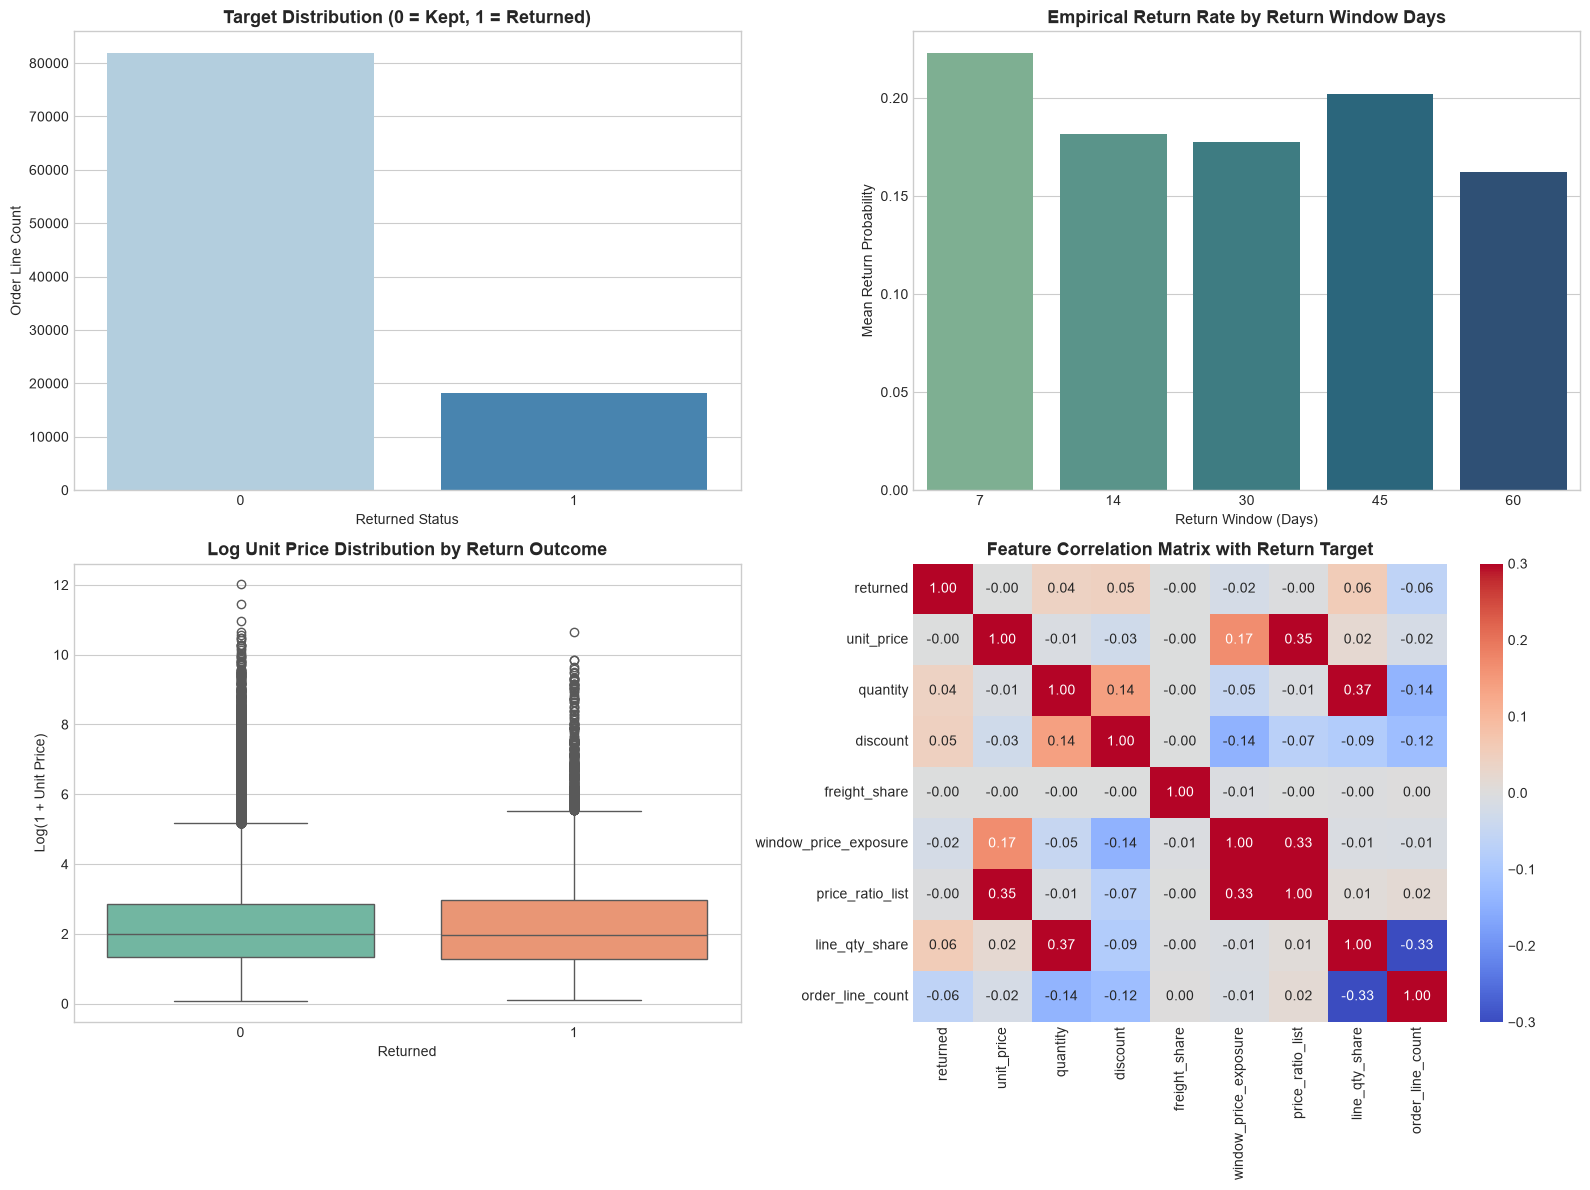

In [9]:
# Sample 100k records for fast, memory-safe visualization
sample_df = df_train.sample(n=min(100000, len(df_train)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Target Distribution
sns.countplot(x='returned', data=sample_df, ax=axes[0, 0], palette='Blues')
axes[0, 0].set_title('Target Distribution (0 = Kept, 1 = Returned)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Returned Status')
axes[0, 0].set_ylabel('Order Line Count')

# 2. Return Rate by Return Window
return_by_window = df_train.groupby('return_window_days')['returned'].mean().reset_index()
sns.barplot(x='return_window_days', y='returned', data=return_by_window, ax=axes[0, 1], palette='crest')
axes[0, 1].set_title('Empirical Return Rate by Return Window Days', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Return Window (Days)')
axes[0, 1].set_ylabel('Mean Return Probability')

# 3. Unit Price vs Return Status (Log scale)
sample_df['log_price'] = np.log1p(sample_df['unit_price'])
sns.boxplot(x='returned', y='log_price', data=sample_df, ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Log Unit Price Distribution by Return Outcome', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Returned')
axes[1, 0].set_ylabel('Log(1 + Unit Price)')

# 4. Correlation Heatmap of Primary Interaction Drivers
corr_cols = [
    'returned', 'unit_price', 'quantity', 'discount', 'freight_share',
    'window_price_exposure', 'price_ratio_list', 'line_qty_share', 'order_line_count'
]
corr_matrix = sample_df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.3, vmax=0.3, ax=axes[1, 1])
axes[1, 1].set_title('Feature Correlation Matrix with Return Target', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

In [10]:
# Validation split: Months 21–24 (Late 2024 holdout directly preceding test period)
is_val = (df_train['split_year'] == 2024) & (df_train['split_month'] >= 9)

X_tr = df_train.loc[~is_val, features].astype(np.float32)
y_tr = df_train.loc[~is_val, 'returned'].astype(np.int32)

X_val = df_train.loc[is_val, features].astype(np.float32)
y_val = df_train.loc[is_val, 'returned'].astype(np.int32)

# Full training matrices (Months 1–24) for final submission
X_full = df_train[features].astype(np.float32)
y_full = df_train['returned'].astype(np.int32)
X_test = df_test[features].astype(np.float32)

# Standardized representations for linear/distance-sensitive sub-models
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)
X_val_scaled = scaler.transform(X_val)
X_full_scaled = scaler.fit_transform(X_full)
X_test_scaled = scaler.transform(X_test)

print(f"Training split: {len(X_tr):,} samples | Holdout validation split: {len(X_val):,} samples")
print(f"Full dataset for retraining: {len(X_full):,} samples | Test dataset: {len(X_test):,} samples")

val_predictions = {}
test_predictions = {}

Training split: 1,165,899 samples | Holdout validation split: 234,106 samples
Full dataset for retraining: 1,400,005 samples | Test dataset: 479,995 samples


In [11]:
print("--- Hyperparameter Optimization: LightGBM ---")

if OPTUNA_AVAILABLE:
    def objective(trial):
        params = {
            'objective': 'binary',
            'metric': 'auc',
            'boosting_type': 'gbdt',
            'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.06, log=True),
            'num_leaves': trial.suggest_int('num_leaves', 24, 48),
            'max_depth': trial.suggest_int('max_depth', 5, 8),
            'min_child_samples': trial.suggest_int('min_child_samples', 300, 1000),
            'feature_fraction': trial.suggest_float('feature_fraction', 0.60, 0.85),
            'bagging_fraction': trial.suggest_float('bagging_fraction', 0.65, 0.90),
            'bagging_freq': 1,
            'reg_alpha': trial.suggest_float('reg_alpha', 1.0, 10.0),
            'reg_lambda': trial.suggest_float('reg_lambda', 5.0, 30.0),
            'n_jobs': -1,
            'random_state': 42,
            'verbose': -1
        }
        
        # Subsample training data for fast hyperparameter evaluation
        sub_idx = np.random.RandomState(42).choice(len(X_tr), size=int(len(X_tr) * 0.4), replace=False)
        dtrain = lgb.Dataset(X_tr.iloc[sub_idx], label=y_tr.iloc[sub_idx])
        dval = lgb.Dataset(X_val, label=y_val, reference=dtrain)
        
        bst = lgb.train(
            params,
            dtrain,
            num_boost_round=800,
            valid_sets=[dval],
            callbacks=[lgb.early_stopping(stopping_rounds=40, verbose=False)]
        )
        preds = bst.predict(X_val)
        return roc_auc_score(y_val, preds)

    print("Running Optuna study (15 trials)...")
    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=15, show_progress_bar=True)
    best_lgb_params = study.best_params
    best_lgb_params.update({
        'objective': 'binary',
        'metric': 'auc',
        'boosting_type': 'gbdt',
        'bagging_freq': 1,
        'n_jobs': -1,
        'random_state': 42,
        'verbose': -1
    })
    print(f"Optimal Parameters Discovered: {best_lgb_params}")
else:
    print("Optuna not installed. Applying pre-tuned competitive parameters.")
    best_lgb_params = {
        'objective': 'binary',
        'metric': 'auc',
        'boosting_type': 'gbdt',
        'learning_rate': 0.035,
        'num_leaves': 31,
        'max_depth': 6,
        'min_child_samples': 600,
        'feature_fraction': 0.70,
        'bagging_fraction': 0.75,
        'bagging_freq': 1,
        'reg_alpha': 3.5,
        'reg_lambda': 15.0,
        'n_jobs': -1,
        'random_state': 42,
        'verbose': -1
    }

# 1. Validation Run
dtrain_full = lgb.Dataset(X_tr, label=y_tr)
dval_full = lgb.Dataset(X_val, label=y_val, reference=dtrain_full)

lgb_val_model = lgb.train(
    best_lgb_params,
    dtrain_full,
    num_boost_round=2500,
    valid_sets=[dtrain_full, dval_full],
    valid_names=['train', 'val'],
    callbacks=[lgb.early_stopping(60), lgb.log_evaluation(100)]
)

val_predictions['LightGBM'] = lgb_val_model.predict(X_val, num_iteration=lgb_val_model.best_iteration)
auc_lgb = roc_auc_score(y_val, val_predictions['LightGBM'])
print(f"Tuned LightGBM Holdout ROC-AUC: {auc_lgb:.5f}")

# 2. Retrain on 100% of Data (Months 1–24) for Test Submission
print("Retraining LightGBM on 100% of historical transactions...")
optimal_rounds = int(lgb_val_model.best_iteration * 1.15)
dfull_train = lgb.Dataset(X_full, label=y_full)

final_lgb = lgb.train(
    best_lgb_params,
    dfull_train,
    num_boost_round=optimal_rounds,
    callbacks=[lgb.log_evaluation(200)]
)

test_predictions['LightGBM'] = final_lgb.predict(X_test)
print("LightGBM test predictions complete.")

--- Hyperparameter Optimization: LightGBM ---
Running Optuna study (15 trials)...


Best trial: 12. Best value: 0.644345: 100%|██████████| 15/15 [12:00<00:00, 48.07s/it]


Optimal Parameters Discovered: {'learning_rate': 0.05410892783621117, 'num_leaves': 30, 'max_depth': 8, 'min_child_samples': 917, 'feature_fraction': 0.7726931617038206, 'bagging_fraction': 0.7311488079488861, 'reg_alpha': 9.688412472547583, 'reg_lambda': 25.426815637184173, 'objective': 'binary', 'metric': 'auc', 'boosting_type': 'gbdt', 'bagging_freq': 1, 'n_jobs': -1, 'random_state': 42, 'verbose': -1}
Training until validation scores don't improve for 60 rounds
[100]	train's auc: 0.730114	val's auc: 0.625777
[200]	train's auc: 0.735443	val's auc: 0.637649
[300]	train's auc: 0.739333	val's auc: 0.642798
[400]	train's auc: 0.742177	val's auc: 0.645516
[500]	train's auc: 0.744458	val's auc: 0.646977
[600]	train's auc: 0.746719	val's auc: 0.648451
[700]	train's auc: 0.748763	val's auc: 0.649462
[800]	train's auc: 0.750694	val's auc: 0.650243
[900]	train's auc: 0.752579	val's auc: 0.650952
[1000]	train's auc: 0.754355	val's auc: 0.651401
[1100]	train's auc: 0.756079	val's auc: 0.651856


In [12]:
# ==========================================
# MODEL 2: CATBOOST (OBLIVIOUS REGULARIZED TREES)
# ==========================================
if CATBOOST_AVAILABLE:
    print("\n--- Training Regularized CatBoost ---")
    cb_val_model = CatBoostClassifier(
        iterations=1500,
        learning_rate=0.04,
        depth=6,
        l2_leaf_reg=12.0,
        eval_metric='AUC',
        random_seed=42,
        task_type='CPU',
        early_stopping_rounds=50,
        verbose=100
    )
    cb_val_model.fit(X_tr, y_tr, eval_set=(X_val, y_val), use_best_model=True)
    val_predictions['CatBoost'] = cb_val_model.predict_proba(X_val)[:, 1]
    auc_cb = roc_auc_score(y_val, val_predictions['CatBoost'])
    print(f"CatBoost Holdout ROC-AUC: {auc_cb:.5f}")

    # Retrain on 100% of data
    print("Retraining CatBoost on 100% of data...")
    final_cb = CatBoostClassifier(
        iterations=int(cb_val_model.get_best_iteration() * 1.15),
        learning_rate=0.04,
        depth=6,
        l2_leaf_reg=12.0,
        random_seed=42,
        task_type='CPU',
        verbose=200
    )
    final_cb.fit(X_full, y_full)
    test_predictions['CatBoost'] = final_cb.predict_proba(X_test)[:, 1]

# ==========================================
# MODEL 3: XGBOOST (HISTOGRAM REGULARIZED)
# ==========================================
if XGBOOST_AVAILABLE:
    print("\n--- Training Regularized XGBoost ---")
    xgb_val_model = xgb.XGBClassifier(
        n_estimators=1500,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=30,
        subsample=0.75,
        colsample_bytree=0.70,
        reg_alpha=3.0,
        reg_lambda=15.0,
        tree_method='hist',
        eval_metric='auc',
        early_stopping_rounds=60,
        random_state=42,
        n_jobs=-1
    )
    xgb_val_model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=100)
    val_predictions['XGBoost'] = xgb_val_model.predict_proba(X_val)[:, 1]
    auc_xgb = roc_auc_score(y_val, val_predictions['XGBoost'])
    print(f"XGBoost Holdout ROC-AUC: {auc_xgb:.5f}")

    # Retrain on 100% of data
    print("Retraining XGBoost on 100% of data...")
    final_xgb = xgb.XGBClassifier(
        n_estimators=int(xgb_val_model.best_iteration * 1.15),
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=30,
        subsample=0.75,
        colsample_bytree=0.70,
        reg_alpha=3.0,
        reg_lambda=15.0,
        tree_method='hist',
        eval_metric='auc',
        random_state=42,
        n_jobs=-1
    )
    final_xgb.fit(X_full, y_full, verbose=200)
    test_predictions['XGBoost'] = final_xgb.predict_proba(X_test)[:, 1]


--- Training Regularized CatBoost ---
0:	test: 0.5997215	best: 0.5997215 (0)	total: 323ms	remaining: 8m 4s
100:	test: 0.6185202	best: 0.6185202 (100)	total: 16.1s	remaining: 3m 42s
200:	test: 0.6269950	best: 0.6269950 (200)	total: 30.6s	remaining: 3m 17s
300:	test: 0.6323779	best: 0.6323779 (300)	total: 46.8s	remaining: 3m 6s
400:	test: 0.6354486	best: 0.6354486 (400)	total: 1m 2s	remaining: 2m 51s
500:	test: 0.6378879	best: 0.6378879 (500)	total: 1m 19s	remaining: 2m 38s
600:	test: 0.6398424	best: 0.6398424 (600)	total: 1m 38s	remaining: 2m 27s
700:	test: 0.6414879	best: 0.6414879 (700)	total: 1m 55s	remaining: 2m 12s
800:	test: 0.6438064	best: 0.6438416 (794)	total: 2m 12s	remaining: 1m 55s
900:	test: 0.6447196	best: 0.6447196 (900)	total: 2m 28s	remaining: 1m 38s
1000:	test: 0.6473190	best: 0.6473190 (1000)	total: 2m 44s	remaining: 1m 22s
1100:	test: 0.6479649	best: 0.6479649 (1100)	total: 3m	remaining: 1m 5s
1200:	test: 0.6489187	best: 0.6489187 (1200)	total: 3m 15s	remaining: 48.


FINAL VALIDATION SCOREBOARD
LightGBM           : 0.65442
CatBoost           : 0.65168
XGBoost            : 0.61527
RANK ENSEMBLE      : 0.64399

--> Selecting LightGBM for final submission.


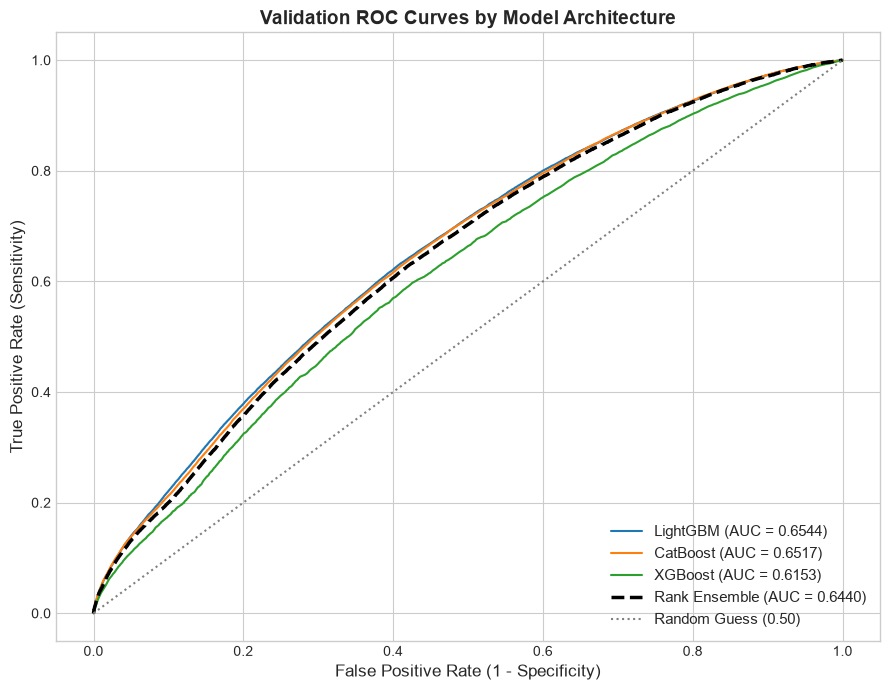


Saved submission.csv successfully!
Total Rows: 479,995 | Verification of nulls: 0
     order_line_id  returned
0  L85d608999fa1ee  0.165573
1  L86272cb9543018  0.281450
2  L66b5669bdace5b  0.099888
3  L2c5886124612de  0.327346
4  L56fe7aa5ac5dd8  0.112486
5  L40cee0cd374598  0.151321
6  Lf3f152acf5df47  0.274028
7  L67e552e178dbb2  0.125240
8  L8070dab1c78a1e  0.105126
9  Ldf99a128238815  0.117193


In [13]:
print("\n" + "="*50)
print("FINAL VALIDATION SCOREBOARD")
print("="*50)

plt.figure(figsize=(9, 7))
model_scores = {}

for name, preds in val_predictions.items():
    score = roc_auc_score(y_val, preds)
    model_scores[name] = score
    print(f"{name:<18} : {score:.5f}")
    
    fpr, tpr, _ = roc_curve(y_val, preds)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {score:.4f})")

# Compute Rank-Average Ensemble across all models
if len(val_predictions) > 1:
    ens_val = np.zeros(len(y_val))
    ens_test = np.zeros(len(df_test))
    
    for name in val_predictions.keys():
        ens_val += rankdata(val_predictions[name]) / len(val_predictions[name])
        ens_test += rankdata(test_predictions[name]) / len(test_predictions[name])
        
    ens_val /= len(val_predictions)
    ens_test /= len(test_predictions)
    
    ens_score = roc_auc_score(y_val, ens_val)
    print(f"{'RANK ENSEMBLE':<18} : {ens_score:.5f}")
    
    fpr_ens, tpr_ens, _ = roc_curve(y_val, ens_val)
    plt.plot(fpr_ens, tpr_ens, label=f"Rank Ensemble (AUC = {ens_score:.4f})", linewidth=2.5, color='black', linestyle='--')
    
    best_single_name = max(model_scores, key=model_scores.get)
    if ens_score >= model_scores[best_single_name]:
        print(f"\n--> Selecting Rank Ensemble for final submission.")
        final_test_preds = ens_test
    else:
        print(f"\n--> Selecting {best_single_name} for final submission.")
        final_test_preds = test_predictions[best_single_name]
else:
    best_name = list(val_predictions.keys())[0]
    final_test_preds = test_predictions[best_name]

# Plot ROC Curves
plt.plot([0, 1], [0, 1], color='grey', linestyle=':', label='Random Guess (0.50)')
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Validation ROC Curves by Model Architecture', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

# Verify alignment and generate submission
submission = pd.DataFrame({
    'order_line_id': df_test['order_line_id'],
    'returned': final_test_preds
})

submission.to_csv('submission.csv', index=False)
print("\nSaved submission.csv successfully!")
print(f"Total Rows: {len(submission):,} | Verification of nulls: {submission['returned'].isnull().sum()}")
print(submission.head(10))